# 04 · Análisis exploratorio (EDA) y correlación

**Entrada:** `data/clean/<estación>/<estación>_horario_limpio.csv` (notebook 03).

**Objetivo:** conocer cómo se comportan el nivel, la lluvia y la temperatura en **La Lindosa** y **Los Micos** antes de construir modelos de predicción, y medir qué tan relacionadas están las variables entre sí.

**Regla importante de este notebook:** las estadísticas y correlaciones se calculan solo con valores **REAL** (observados). Si se incluyeran los valores imputados, el análisis mediría en parte el método de relleno y no el río. Excepciones: las gráficas de serie completa muestran los valores imputados (resaltados), y los **totales y acumulados de lluvia** (anuales, mensuales y ventanas de lluvia acumulada) usan la lluvia final con imputados, porque una suma con horas vacías quedaría cortada. La lluvia imputada es 5,5 % de las horas en La Lindosa y 8,3 % en Los Micos.

Contenido:

1. Estadística descriptiva
2. Resumen por año
3. Series completas
4. Estacionalidad (meses) y ciclo diario (horas)
5. Eventos extremos (percentil 95)
6. Matriz de correlación
7. Lluvia acumulada y retraso de la respuesta del río
8. Relación entre las dos estaciones
9. Conclusiones

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN = RAIZ / "data" / "clean"
ESTACIONES = ["La_Lindosa", "Los_Micos"]
NOMBRE = {"La_Lindosa": "La Lindosa", "Los_Micos": "Los Micos"}
VARIABLES = ["nivel_m", "temperatura_c", "lluvia_mm"]
COLOR = {"La_Lindosa": "#1d3557", "Los_Micos": "#e76f51"}

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.2f}".format)

limpio, real = {}, {}
for est in ESTACIONES:
    df = pd.read_csv(CLEAN / est / f"{est}_horario_limpio.csv", parse_dates=["fecha_hora"], index_col="fecha_hora")
    limpio[est] = df
    # versión "solo REAL": cada variable vale NaN donde fue imputada
    real[est] = pd.DataFrame({v: df[v].where(df[f"{v}_calidad"] == "REAL") for v in VARIABLES})
    print(f"{est}: {len(df):,} horas, {df.index.min():%Y-%m-%d} a {df.index.max():%Y-%m-%d}")

La_Lindosa: 74,726 horas, 2017-06-23 a 2025-12-31
Los_Micos: 74,716 horas, 2017-06-23 a 2025-12-31


## 1. Estadística descriptiva (solo valores REAL)

In [2]:
tablas = []
for est in ESTACIONES:
    d = real[est].describe(percentiles=[0.05, 0.5, 0.95]).T
    d.insert(0, "estación", NOMBRE[est])
    tablas.append(d)
pd.concat(tablas)

,estación,count,mean,std,min,5%,50%,95%,max
nivel_m,La Lindosa,"69,491.00",0.80,0.16,0.39,0.56,0.80,1.03,3.11
temperatura_c,La Lindosa,"64,924.00",22.67,3.68,10.04,17.80,21.96,29.16,34.42
lluvia_mm,La Lindosa,"70,614.00",0.12,1.02,0.00,0.00,0.00,0.30,52.00
nivel_m,Los Micos,"67,242.00",0.37,0.14,0.05,0.14,0.38,0.57,1.82
temperatura_c,Los Micos,"69,096.00",23.22,3.99,13.32,18.23,22.02,30.60,38.18
lluvia_mm,Los Micos,"68,527.00",0.11,1.00,0.00,0.00,0.00,0.20,54.50


**Lectura:**

- **Nivel:** La Lindosa tiene una lámina de agua más alta (mediana 0,80 m) que Los Micos (mediana 0,38 m), y las dos tienen una distribución muy asimétrica: el 95 % del tiempo el nivel está por debajo de 1,03 m en La Lindosa y de 0,57 m en Los Micos, pero en crecida llega a 3,11 m y 1,82 m (4 a 5 veces la mediana). Esto es típico de ríos de montaña y es justamente lo que un modelo de alerta debe aprender.
- **Lluvia:** la mediana horaria es 0: llueve en una fracción pequeña de las horas, y cuando llueve puede ser intenso (máximos de 50 mm en una hora).
- **Temperatura:** entre 10 y 38 °C, con media de unos 23 °C; Los Micos es algo más cálida.

## 2. Resumen por año

Lluvia anual total (con valores imputados, porque una suma necesita todas las horas, y se indica qué parte es imputada), nivel mediano y máximo, y temperatura media.

In [3]:
for est in ESTACIONES:
    df, r = limpio[est], real[est]
    anual = pd.DataFrame({
        "lluvia total (mm)": df.lluvia_mm.groupby(df.index.year).sum(),
        "% lluvia imputada": (df.lluvia_mm_calidad != "REAL").groupby(df.index.year).mean() * 100,
        "nivel mediano (m)": r.nivel_m.groupby(r.index.year).median(),
        "nivel P95 (m)": r.nivel_m.groupby(r.index.year).quantile(0.95),
        "nivel máximo (m)": r.nivel_m.groupby(r.index.year).max(),
        "temperatura media (°C)": r.temperatura_c.groupby(r.index.year).mean(),
    })
    anual.index.name = "año"
    print(NOMBRE[est])
    display(anual)

La Lindosa


,lluvia total (mm),% lluvia imputada,nivel mediano (m),nivel P95 (m),nivel máximo (m),temperatura media (°C)
año,,,,,,
2017,718.32,21.64,0.78,0.93,2.86,23.35
2018,732.93,2.60,0.85,1.00,1.36,23.21
2019,616.48,8.41,0.89,1.04,2.06,23.68
2020,598.60,2.98,0.80,0.99,2.44,23.71
2021,"1,416.63",0.35,0.88,1.10,2.74,22.15
2022,"1,080.38",5.84,0.85,1.16,3.11,21.86
2023,"1,167.12",0.18,0.70,0.96,2.25,23.00
2024,"1,152.68",2.06,0.70,0.88,2.56,22.76
2025,"1,251.49",13.13,0.58,0.75,1.32,19.82


Los Micos


,lluvia total (mm),% lluvia imputada,nivel mediano (m),nivel P95 (m),nivel máximo (m),temperatura media (°C)
año,,,,,,
2017,513.74,17.40,0.45,0.56,1.06,23.83
2018,916.00,2.27,0.44,0.59,1.65,23.77
2019,825.00,4.86,0.40,0.54,1.82,24.15
2020,"1,054.83",18.69,0.46,0.59,1.26,23.37
2021,964.34,17.39,0.22,0.57,1.71,22.32
2022,"1,063.45",1.53,0.18,0.43,1.50,22.18
2023,"1,150.21",0.51,0.33,0.57,1.09,23.44
2024,"1,354.62",9.55,0.45,0.61,1.16,23.68
2025,412.05,6.65,0.28,0.40,0.92,22.71


**Lectura:**

- 2017 es un año incompleto (la serie empieza en junio), así que su lluvia total no se compara con los demás.
- **El nivel "de base" cambia de un año a otro en las dos estaciones.** En Los Micos la mediana baja de ~0,45 m a ~0,2 m en 2021-2022 y luego sube; en La Lindosa baja de ~0,85 m (2018-2022) a 0,70 m (2023-2024) y 0,58 m (2025). Puede ser un cambio real del cauce (sedimentos, erosión) o de la referencia del sensor. Conviene confirmarlo con el operador antes de entrenar con todos los años juntos; si fuera del sensor, habría que corregir el desfase o modelar el **cambio** de nivel en vez del nivel absoluto.
- La Lindosa registra mucha menos lluvia en 2018-2020 (600-730 mm) que en 2021-2025 (1.100-1.400 mm). Los Micos no muestra ese salto en 2018-2019, así que podría ser variabilidad real o un cambio en el pluviómetro de La Lindosa.
- En **Los Micos 2025** la lluvia total es muy baja comparada con los demás años y con La Lindosa del mismo año, aunque casi toda es REAL. Lo más probable es una falla del pluviómetro (obstruido, por ejemplo) y no un año realmente seco; también conviene preguntarlo al operador.

## 3. Series completas

Arriba, el nivel horario (en gris claro las horas imputadas); abajo, la lluvia diaria.

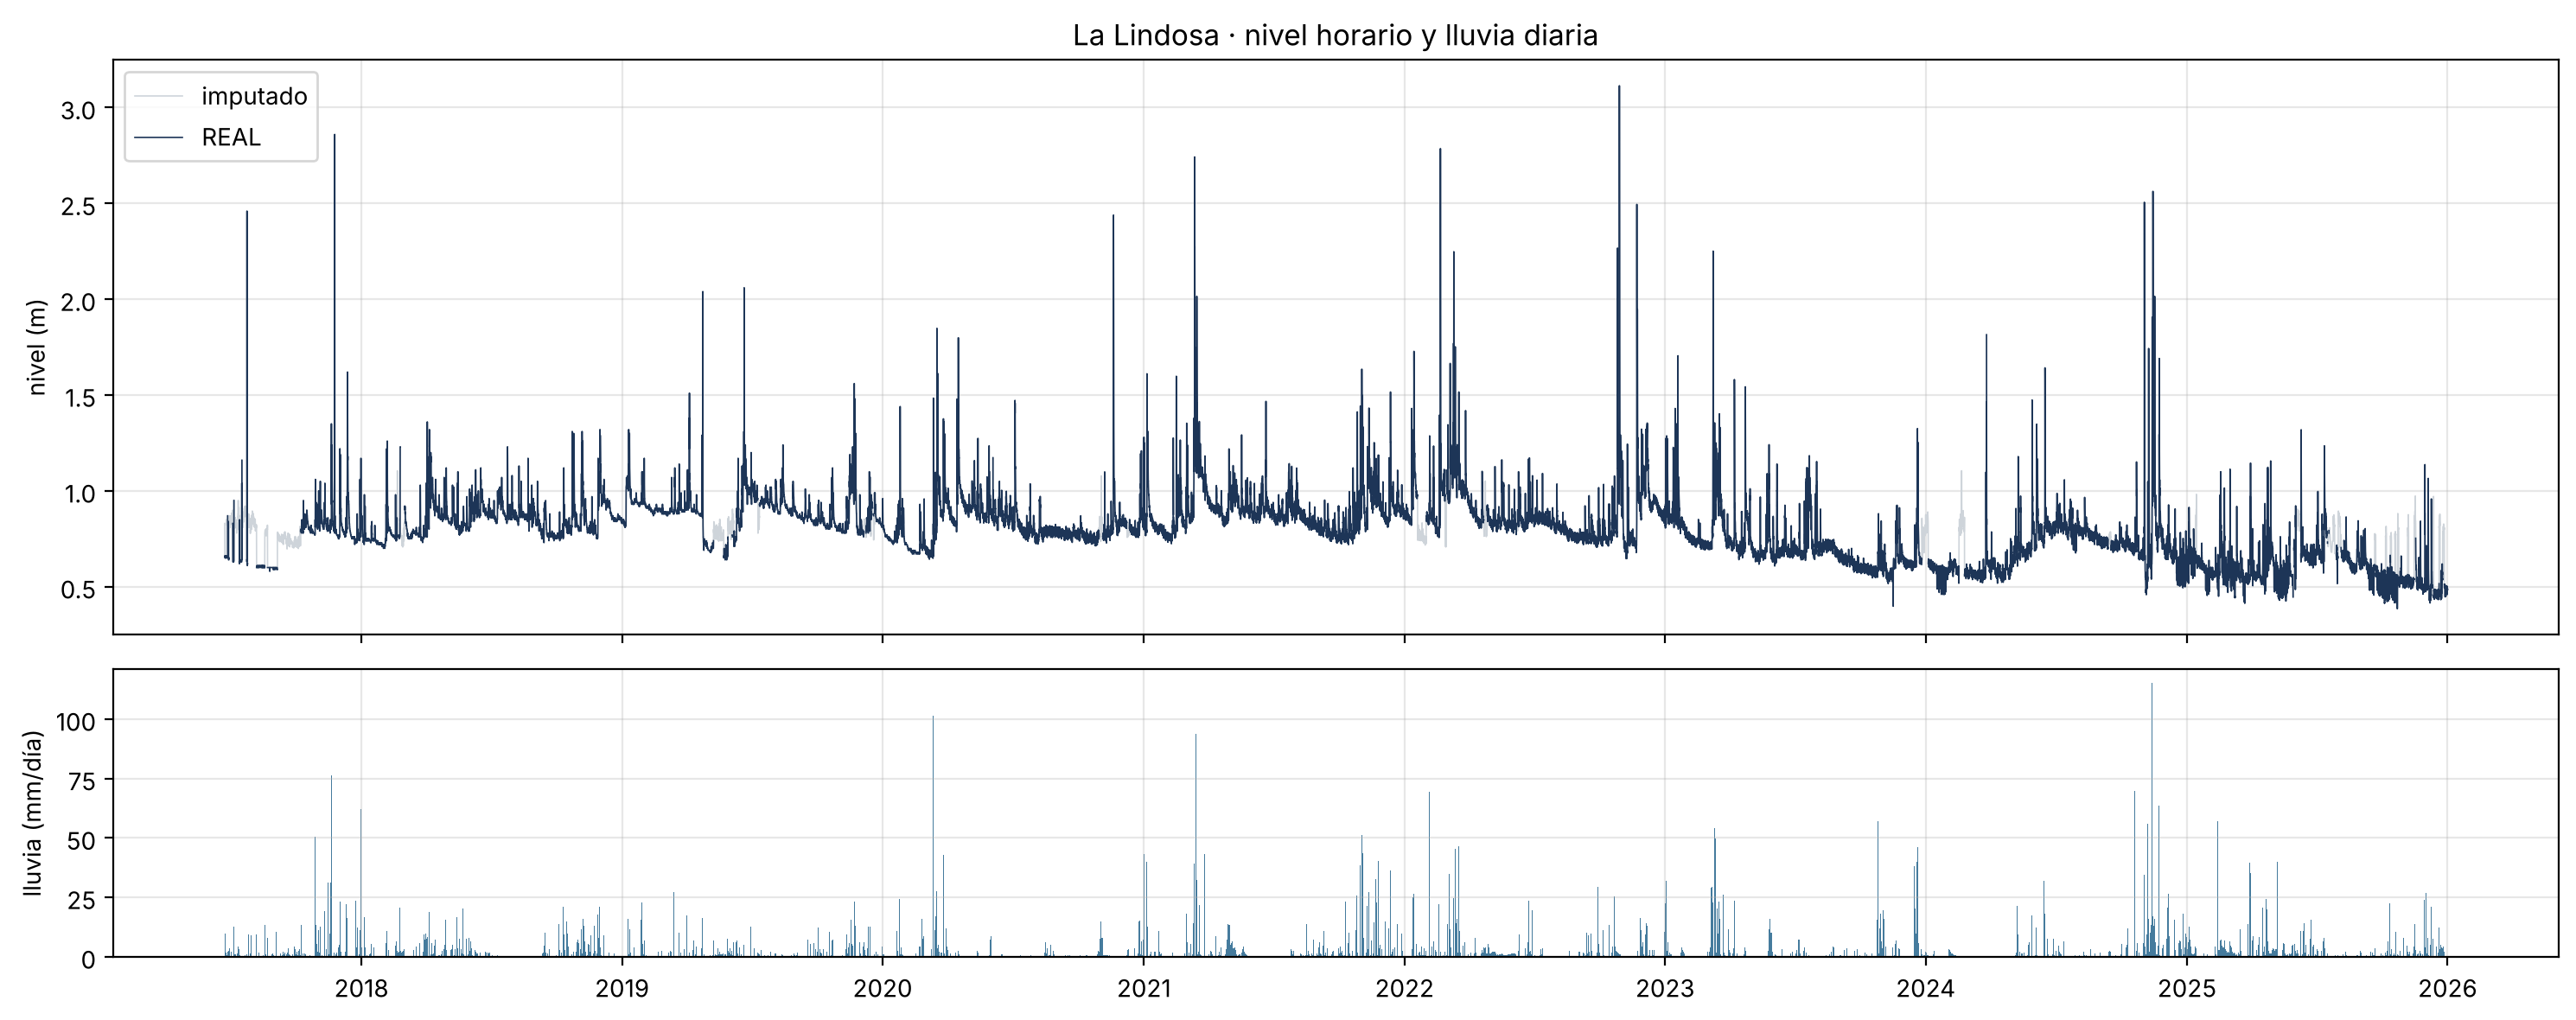

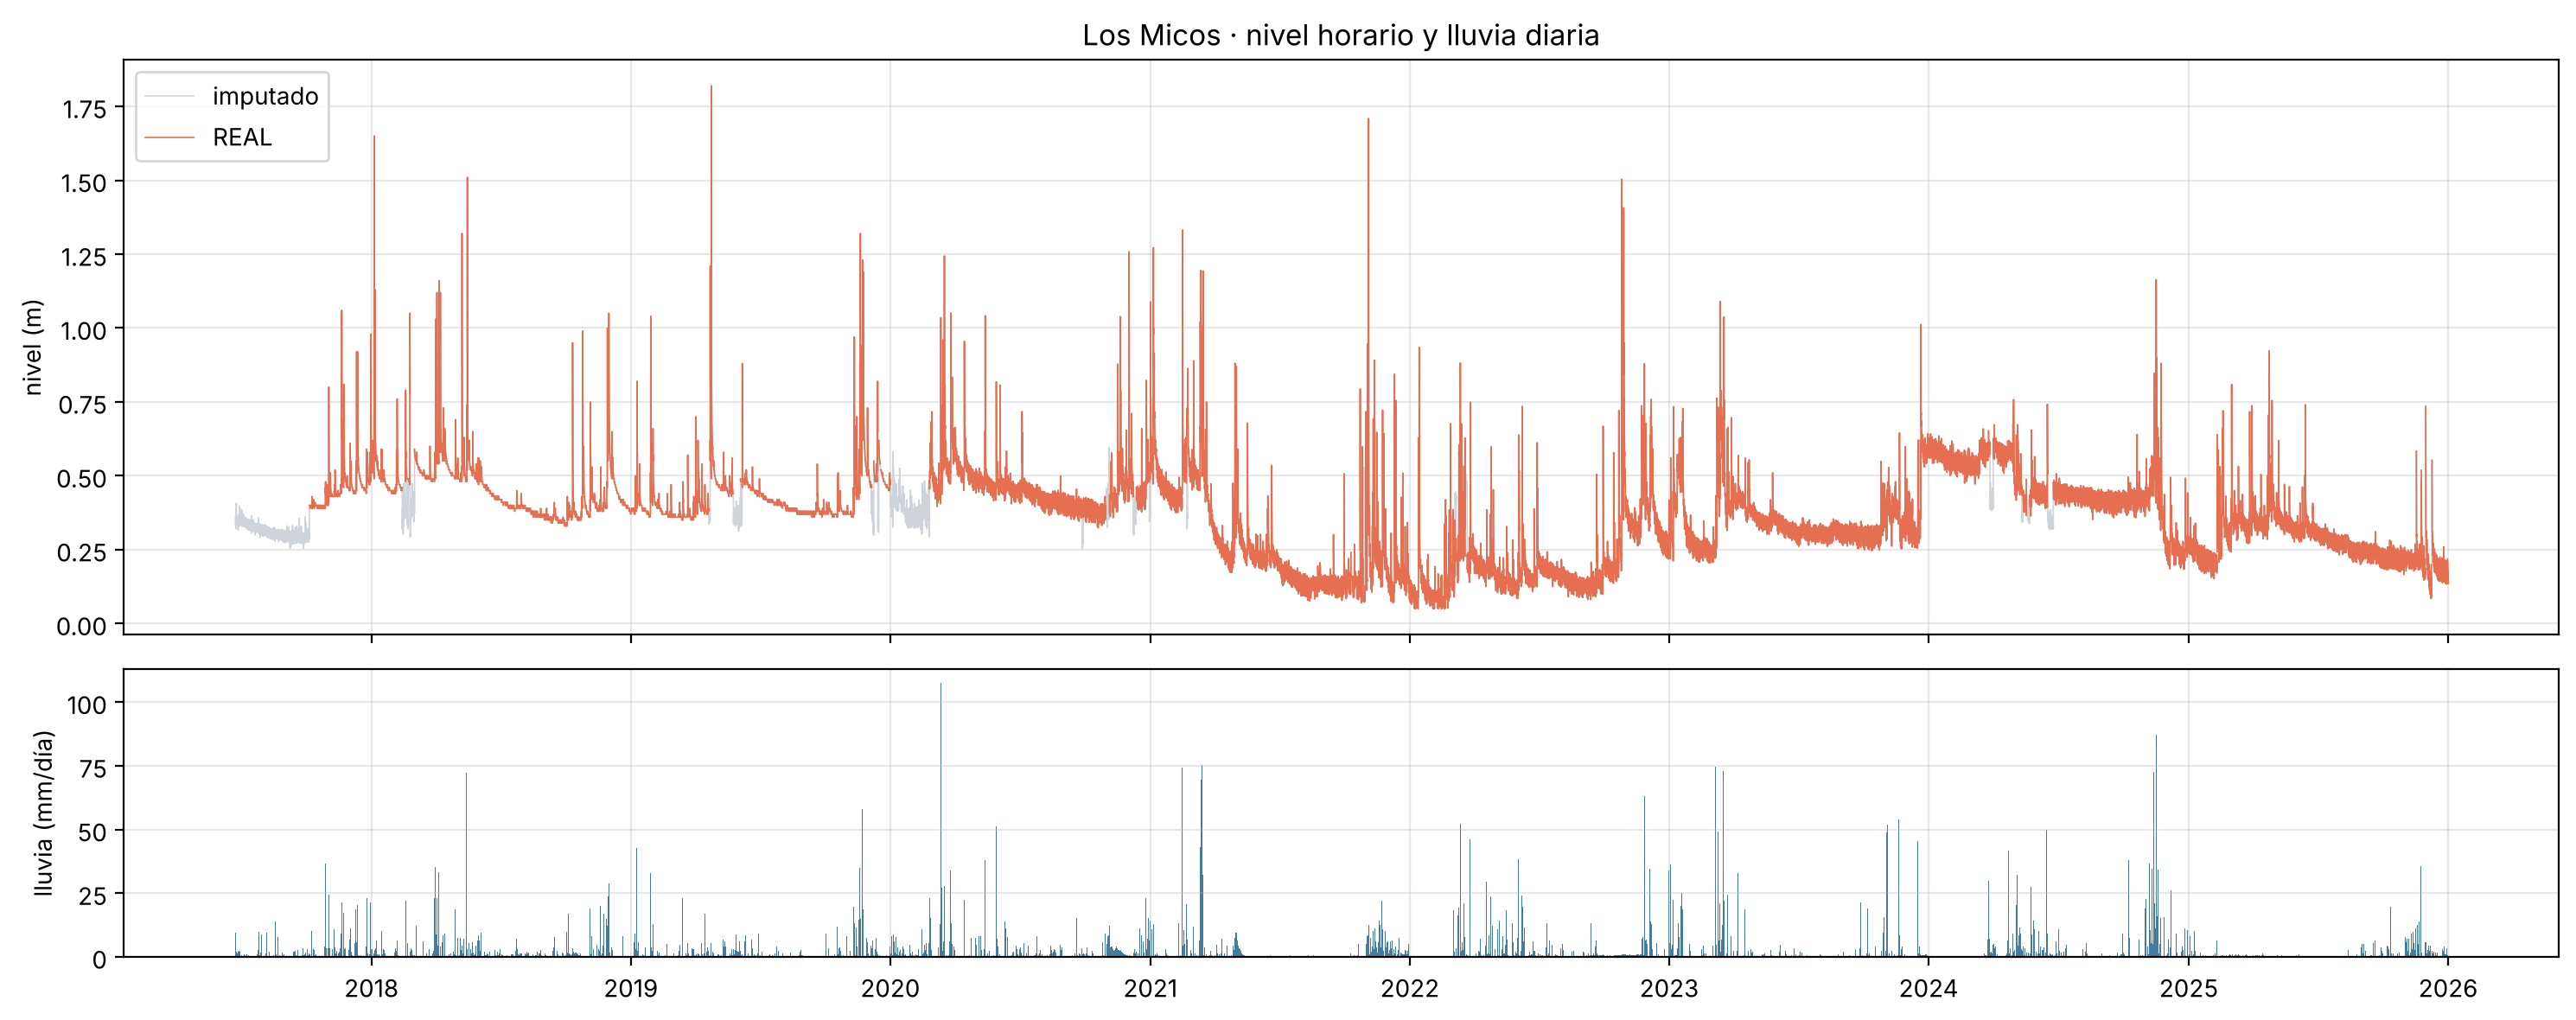

In [4]:
for est in ESTACIONES:
    df = limpio[est]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    ax1.plot(df.index, df.nivel_m, color="#ced4da", lw=0.6, label="imputado")
    ax1.plot(df.index, df.nivel_m.where(df.nivel_m_calidad == "REAL"), color=COLOR[est], lw=0.6, label="REAL")
    ax1.set_ylabel("nivel (m)")
    ax1.set_title(f"{NOMBRE[est]} · nivel horario y lluvia diaria")
    ax1.legend(loc="upper left")
    diaria = df.lluvia_mm.resample("D").sum()
    ax2.bar(diaria.index, diaria.values, width=1, color="#457b9d")
    ax2.set_ylabel("lluvia (mm/día)")
    plt.tight_layout()
    plt.show()

**Lectura:** las crecidas aparecen como picos cortos (horas a pocos días) sobre un nivel de base que baja lentamente en las temporadas secas. En **Los Micos** se ven además **escalones** en el nivel de base que no parecen respuesta a la lluvia: el más claro es el del **22 de diciembre de 2023**, cuando el nivel mínimo diario sube unos 0,24 m de un día para otro y se mantiene así varios meses. Un escalón que no baja después es la huella típica de un cambio de referencia o de reinstalación del sensor; es otro punto para confirmar con el operador.

## 4. Estacionalidad y ciclo diario

### 4.1 Por mes

El clima del Huila es **bimodal**: dos temporadas de lluvia al año (aproximadamente marzo-mayo y octubre-diciembre) separadas por temporadas secas. Si el nivel responde a la lluvia, debería seguir el mismo patrón.

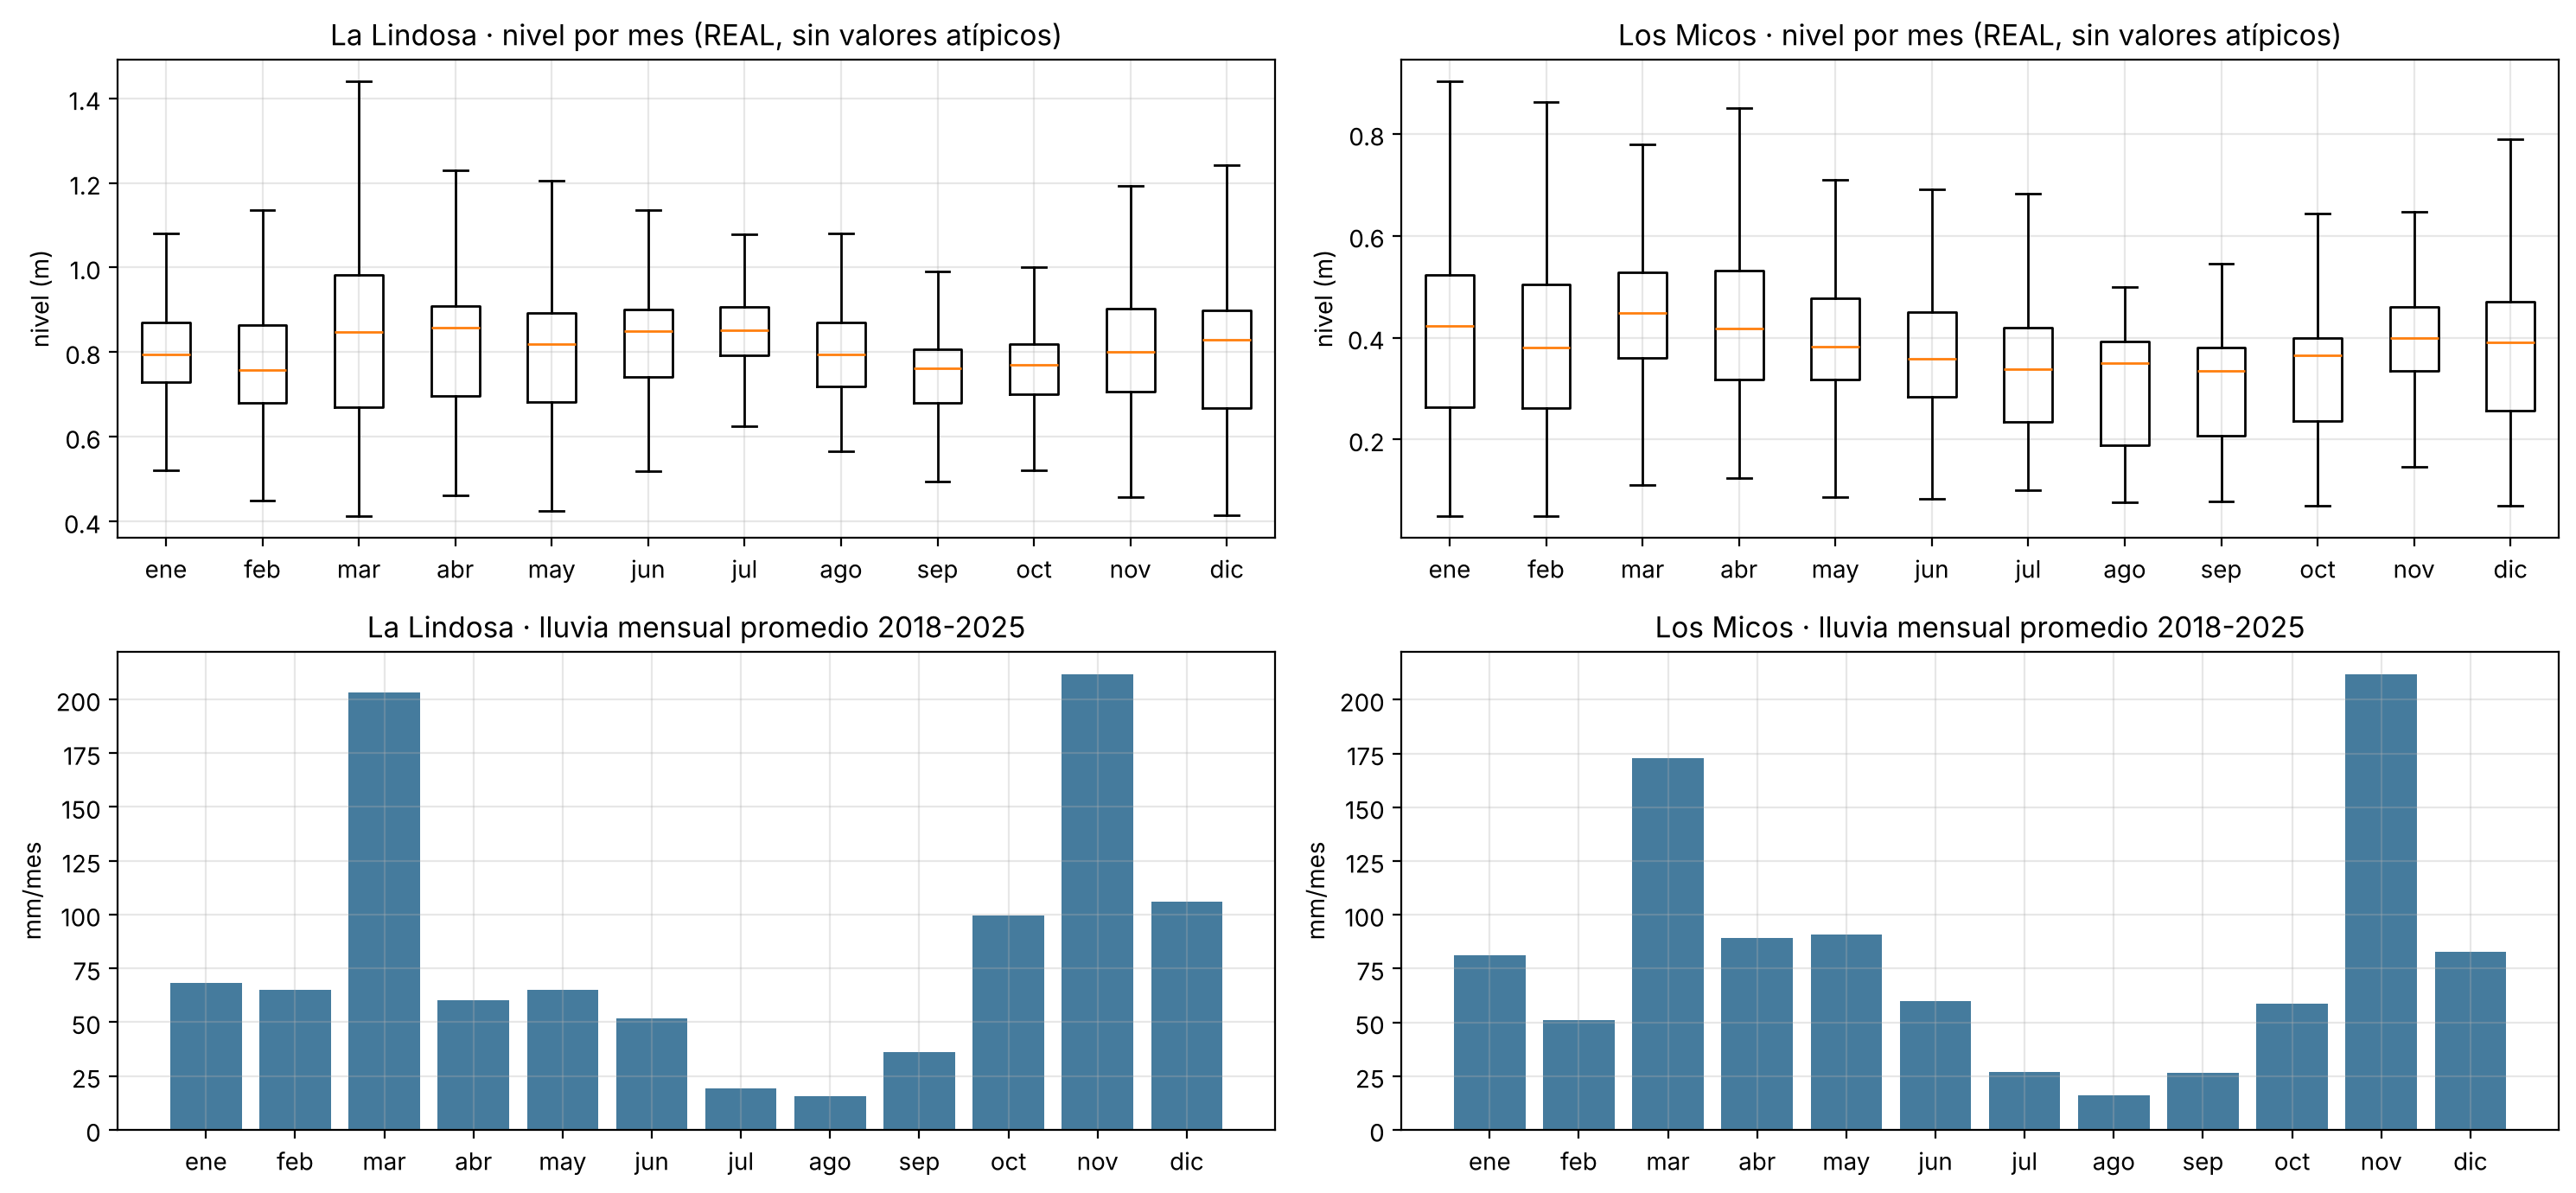

In [5]:
meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for j, est in enumerate(ESTACIONES):
    df, r = limpio[est], real[est]
    datos = [r.nivel_m[r.index.month == m].dropna() for m in range(1, 13)]
    axes[0, j].boxplot(datos, tick_labels=meses, showfliers=False)
    axes[0, j].set_title(f"{NOMBRE[est]} · nivel por mes (REAL, sin valores atípicos)")
    axes[0, j].set_ylabel("nivel (m)")
    lluvia_mes = df.lluvia_mm.resample("MS").sum()
    lluvia_mes = lluvia_mes[lluvia_mes.index.year.isin(range(2018, 2026))]
    prom = lluvia_mes.groupby(lluvia_mes.index.month).mean()
    axes[1, j].bar(meses, prom.values, color="#457b9d")
    axes[1, j].set_title(f"{NOMBRE[est]} · lluvia mensual promedio 2018-2025")
    axes[1, j].set_ylabel("mm/mes")
plt.tight_layout()
plt.show()

### 4.2 Por hora del día

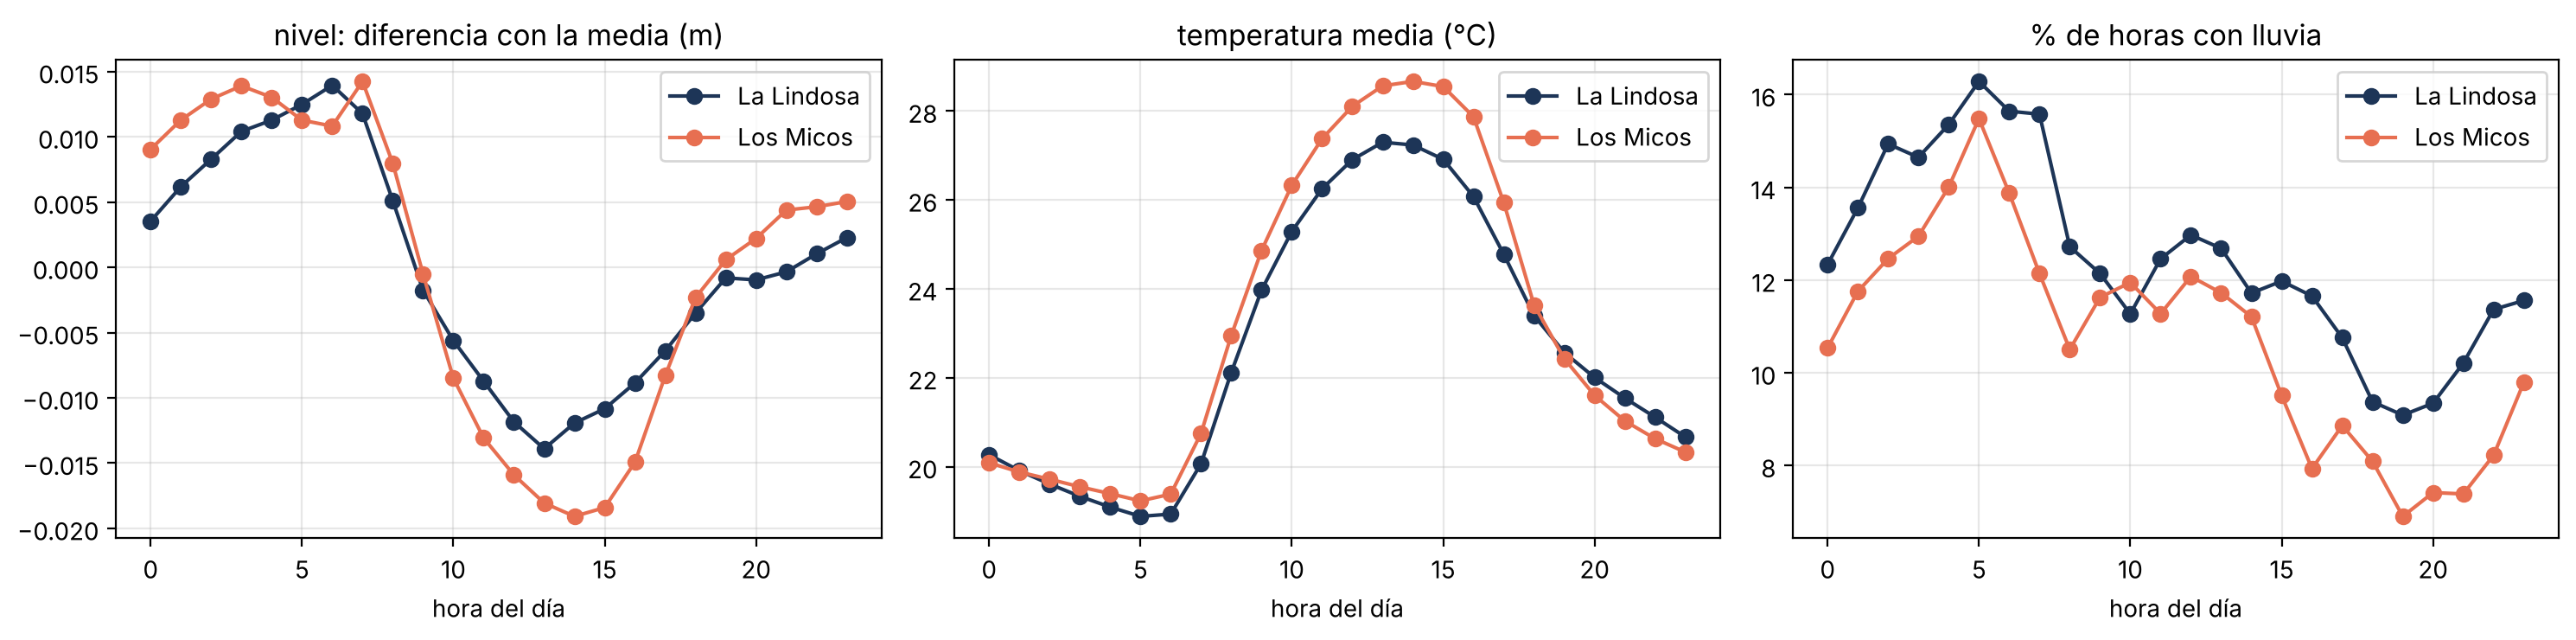

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for est in ESTACIONES:
    r = real[est]
    por_hora = r.groupby(r.index.hour)
    axes[0].plot(por_hora.nivel_m.mean() - r.nivel_m.mean(), color=COLOR[est], marker="o", label=NOMBRE[est])
    axes[1].plot(por_hora.temperatura_c.mean(), color=COLOR[est], marker="o", label=NOMBRE[est])
    axes[2].plot(por_hora.lluvia_mm.apply(lambda s: (s > 0).mean() * 100), color=COLOR[est], marker="o",
                 label=NOMBRE[est])
axes[0].set_title("nivel: diferencia con la media (m)")
axes[1].set_title("temperatura media (°C)")
axes[2].set_title("% de horas con lluvia")
for ax in axes:
    ax.set_xlabel("hora del día")
    ax.legend()
plt.tight_layout()
plt.show()

**Lectura:** la temperatura tiene el ciclo diario esperado (mínima al amanecer, máxima a media tarde). La lluvia es más frecuente en la tarde y la noche (lluvias convectivas). El nivel tiene un ciclo diario pequeño, de pocos centímetros, que es lo que se vio en la semana de ejemplo del notebook 01.

## 5. Eventos extremos (percentil 95)

Como en el artículo, se marca como "evento" cada episodio en que el nivel supera el **percentil 95** de la estación (el valor que solo se supera el 5 % del tiempo). Horas seguidas por encima del umbral cuentan como un solo evento.

In [7]:
for est in ESTACIONES:
    r = real[est]
    p95 = r.nivel_m.quantile(0.95)
    encima = r.nivel_m > p95
    inicio_evento = encima & ~encima.shift(fill_value=False)
    eventos = inicio_evento.groupby(r.index.year).sum()
    print(f"{NOMBRE[est]}: percentil 95 = {p95:.2f} m; mediana = {r.nivel_m.median():.2f} m; "
          f"máximo = {r.nivel_m.max():.2f} m ({r.nivel_m.max() / r.nivel_m.median():.1f} veces la mediana)")
    print("   eventos por año:", eventos.to_dict())
    print("   eventos por mes:", inicio_evento.groupby(r.index.month).sum().to_dict())

La Lindosa: percentil 95 = 1.03 m; mediana = 0.80 m; máximo = 3.11 m (3.9 veces la mediana)
   eventos por año: {2017: 17, 2018: 44, 2019: 60, 2020: 34, 2021: 86, 2022: 75, 2023: 42, 2024: 23, 2025: 11}
   eventos por mes: {1: 24, 2: 25, 3: 69, 4: 30, 5: 37, 6: 31, 7: 28, 8: 21, 9: 1, 10: 20, 11: 75, 12: 31}
Los Micos: percentil 95 = 0.57 m; mediana = 0.38 m; máximo = 1.82 m (4.8 veces la mediana)
   eventos por año: {2017: 10, 2018: 40, 2019: 24, 2020: 41, 2021: 42, 2022: 31, 2023: 41, 2024: 171, 2025: 15}
   eventos por mes: {1: 82, 2: 47, 3: 74, 4: 76, 5: 19, 6: 8, 7: 2, 8: 0, 9: 1, 10: 13, 11: 47, 12: 46}


Los eventos se concentran en las temporadas de lluvias (sobre todo marzo y noviembre), como reporta el artículo. El conteo por año está afectado por el cambio del nivel de base: por ejemplo, Los Micos 2024 tiene 171 eventos porque ese año todo el río estuvo más alto, no necesariamente porque tuviera más crecidas. Para definir umbrales de alerta conviene usar valores absolutos acordados con la CAM, o percentiles calculados por año.

## 6. Matriz de correlación

Se usan dos medidas:

- **Pearson (r):** mide relación **lineal**. Es sensible a valores extremos.
- **Spearman (ρ):** mide si dos variables suben y bajan **juntas** aunque no sea en línea recta (usa rangos). Es más apropiada aquí porque la lluvia y el nivel son muy asimétricos.

Ambas van de −1 (relación inversa perfecta) a +1 (directa perfecta); 0 = sin relación. Como guía: |r| < 0,2 débil, 0,2-0,5 moderada, > 0,5 fuerte.

Se calculan con datos **horarios** y con datos **diarios** (nivel medio, nivel máximo y lluvia total del día), porque a escala diaria el retraso entre la lluvia y la crecida pesa menos.

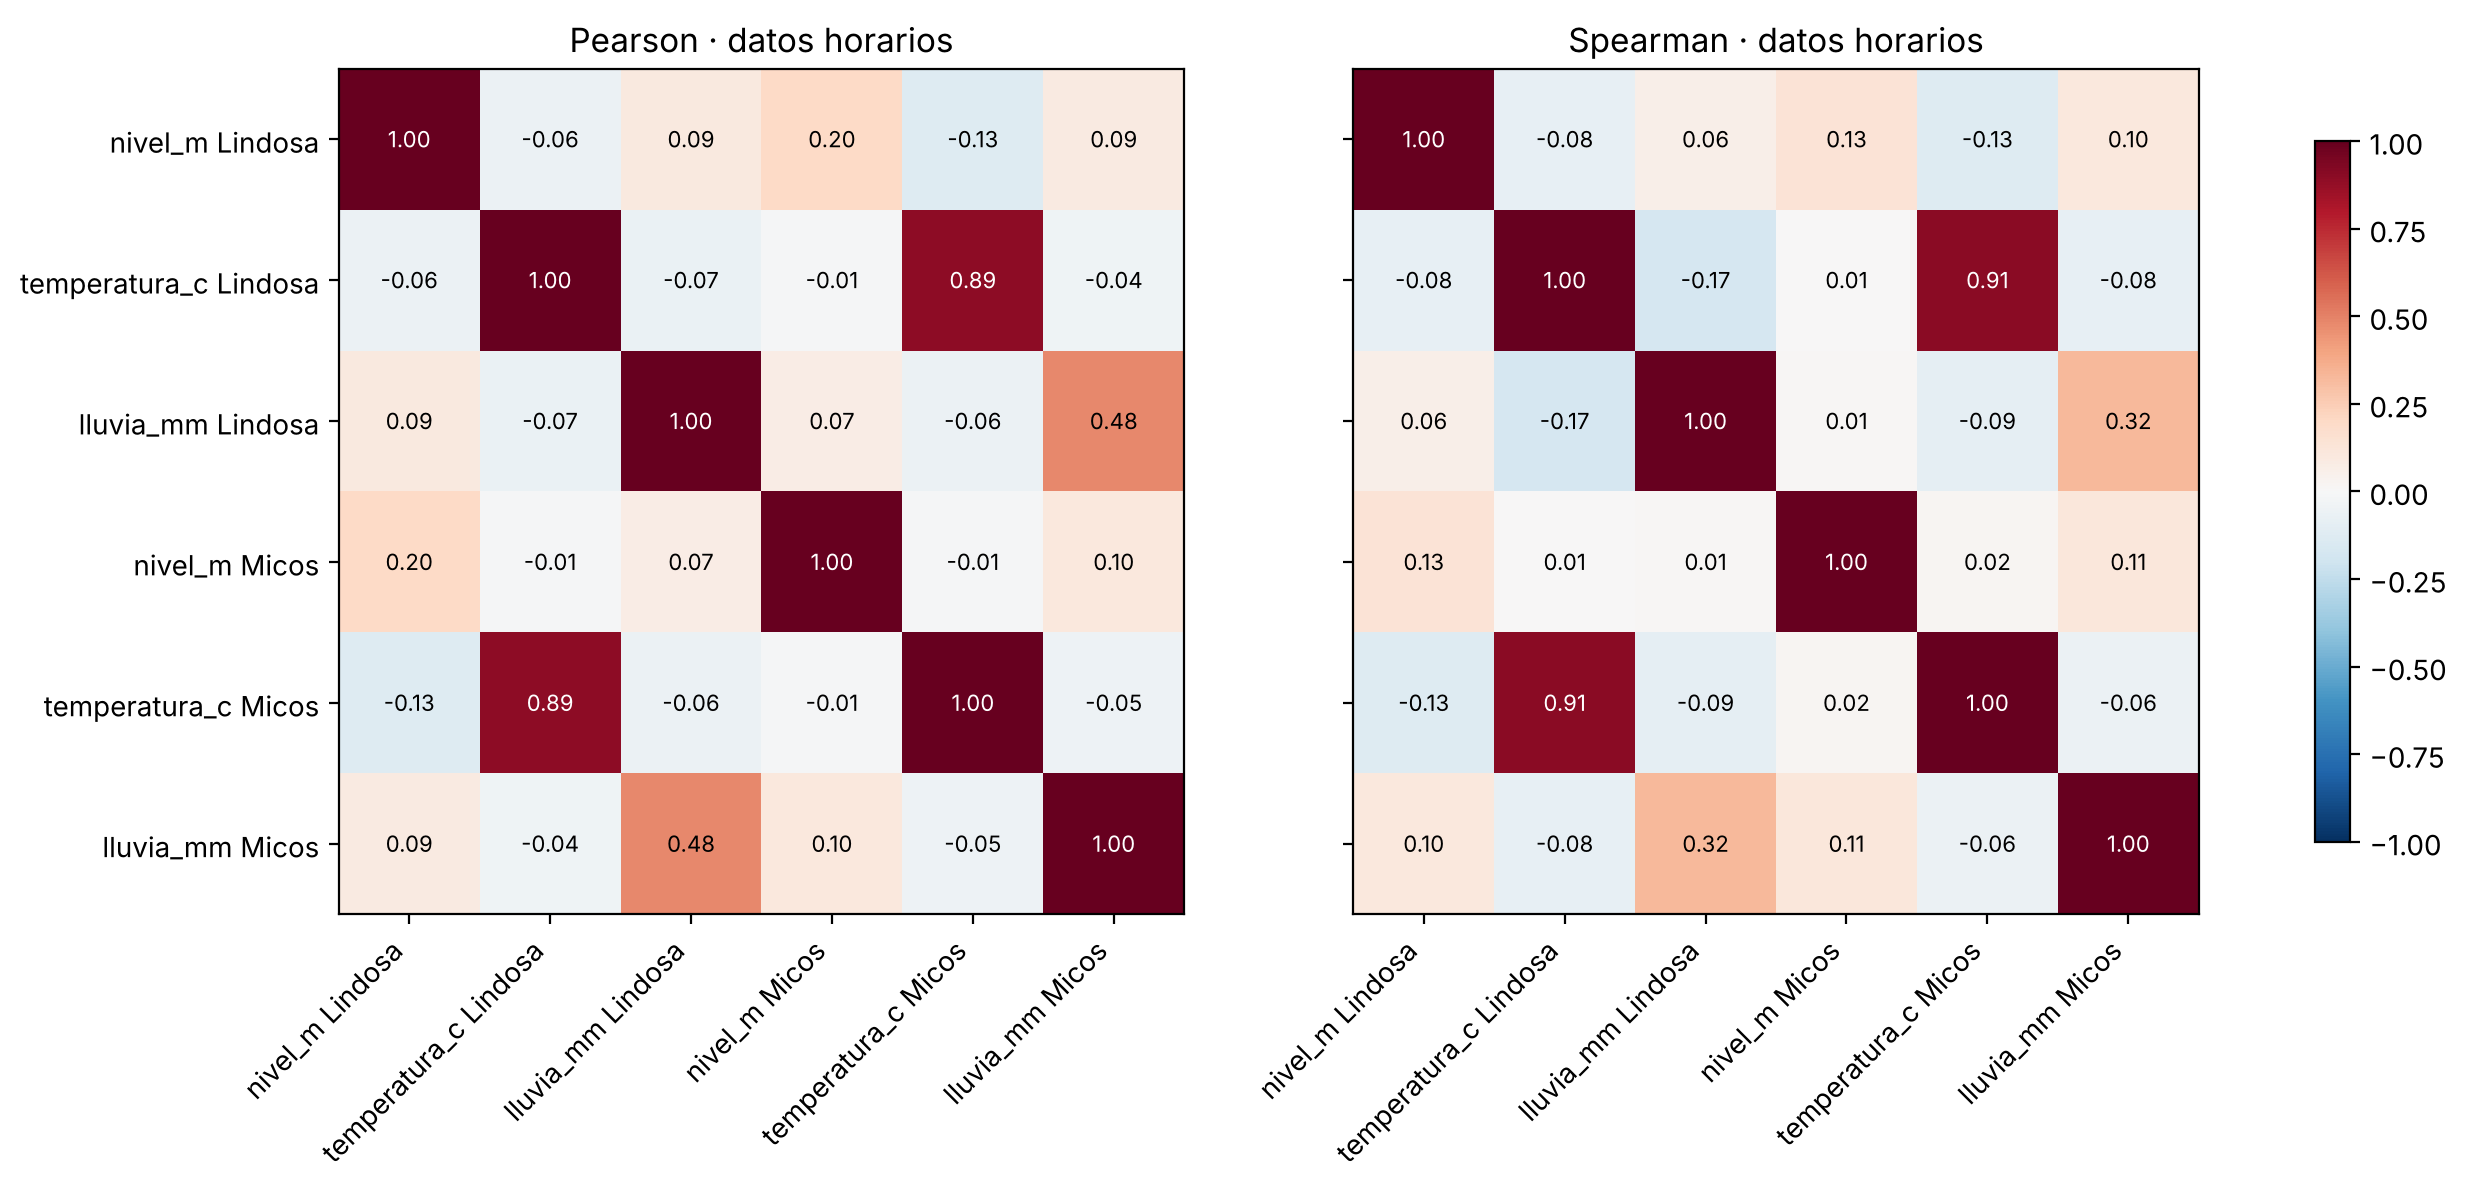

In [8]:
def tabla_conjunta(freq):
    partes = []
    for est in ESTACIONES:
        r = real[est]
        corto = NOMBRE[est].split()[-1]
        if freq == "h":
            d = r.rename(columns=lambda c: f"{c} {corto}")
        else:
            d = pd.DataFrame({
                f"nivel_m {corto}": r.nivel_m.resample("D").mean(),
                f"nivel_max {corto}": r.nivel_m.resample("D").max(),
                f"temperatura_c {corto}": r.temperatura_c.resample("D").mean(),
                # día válido solo si tiene al menos 20 horas de lluvia observadas
                f"lluvia_mm {corto}": r.lluvia_mm.resample("D").sum(min_count=20),
            })
        partes.append(d)
    return pd.concat(partes, axis=1)

def mapa_calor(matriz, titulo, ax, etiquetas_y=True):
    im = ax.imshow(matriz.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(matriz)), matriz.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(matriz)), matriz.index if etiquetas_y else [])
    for (i, j), v in np.ndenumerate(matriz.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else "black")
    ax.set_title(titulo)
    ax.grid(False)
    return im

horaria, diaria = tabla_conjunta("h"), tabla_conjunta("D")
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
mapa_calor(horaria.corr("pearson"), "Pearson · datos horarios", axes[0])
im = mapa_calor(horaria.corr("spearman"), "Spearman · datos horarios", axes[1], etiquetas_y=False)
fig.colorbar(im, ax=axes, shrink=0.7)
plt.show()

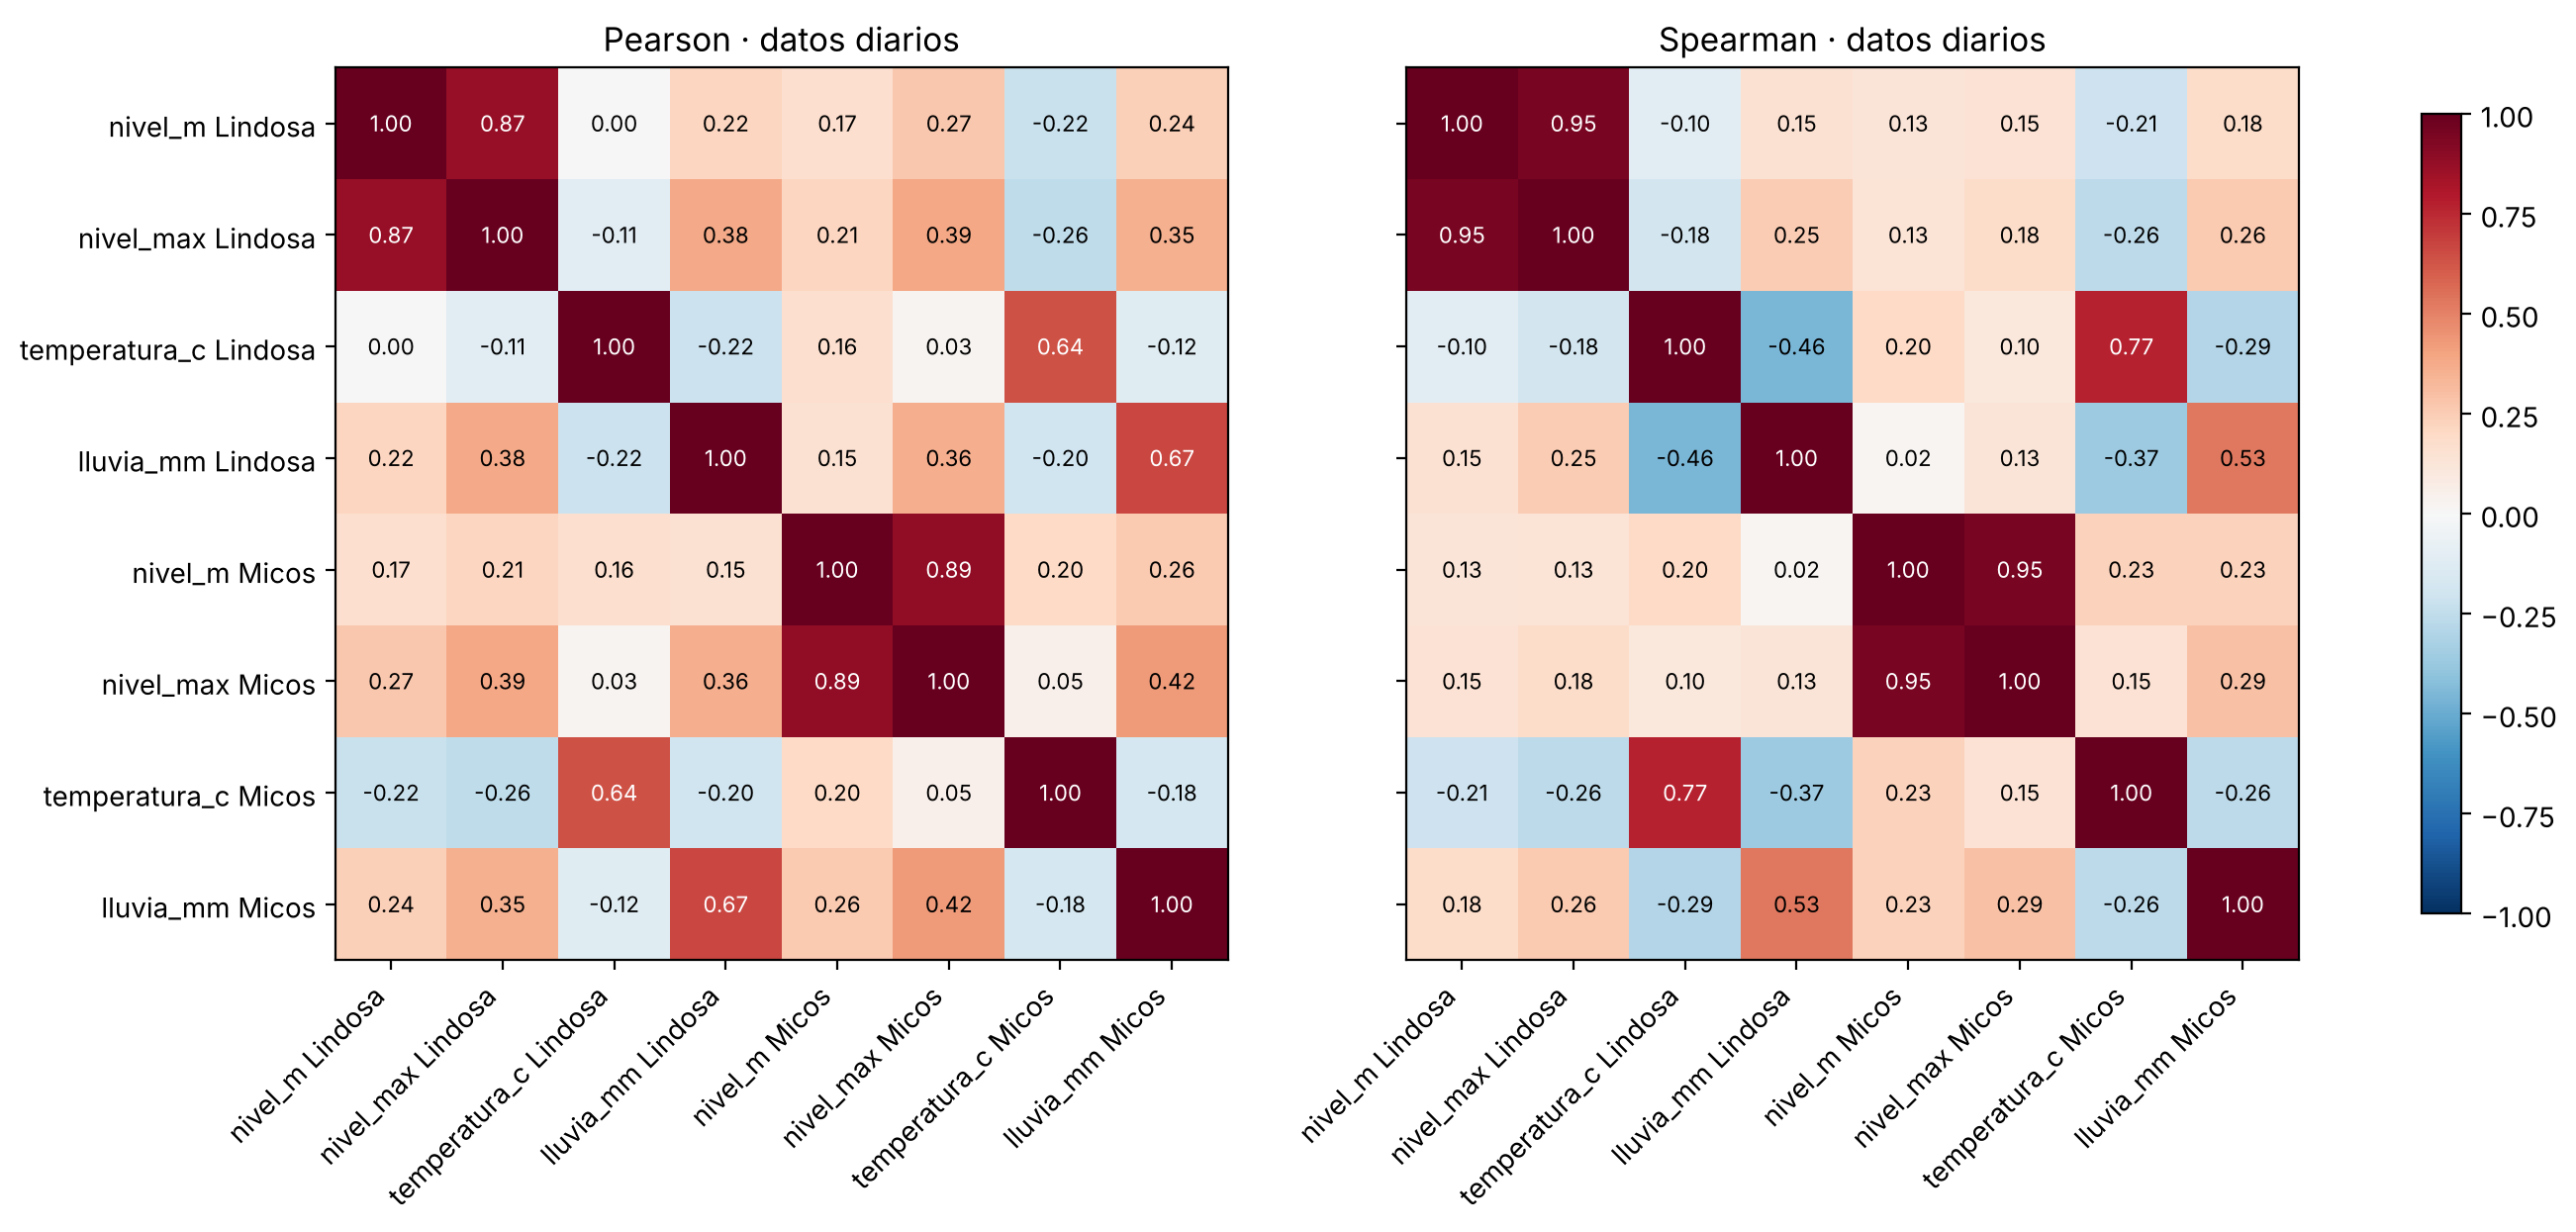

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
mapa_calor(diaria.corr("pearson"), "Pearson · datos diarios", axes[0])
im = mapa_calor(diaria.corr("spearman"), "Spearman · datos diarios", axes[1], etiquetas_y=False)
fig.colorbar(im, ax=axes, shrink=0.7)
plt.show()

## 7. Lluvia acumulada y retraso de la respuesta del río

El artículo encontró que la correlación **instantánea** entre lluvia y nivel es casi cero y advirtió que eso **no** significa que la lluvia sea poco útil: el río tarda en responder, y una correlación hora a hora no captura ese retraso. Aquí se comprueba de dos formas.

### 7.1 Lluvia acumulada en las últimas *N* horas

En vez de la lluvia de la misma hora, se usa la suma de la lluvia de las últimas 1, 3, 6, 12, 24, 48, 72 y 168 horas (una semana). Si la correlación sube con *N*, el río "recuerda" la lluvia de las horas o días anteriores.

Pearson             Spearman          
estación    La Lindosa Los Micos La Lindosa Los Micos
ventana (h)                                          
1                 0.09      0.10       0.06      0.07
3                 0.16      0.19       0.09      0.10
6                 0.20      0.23       0.11      0.11
12                0.23      0.25       0.14      0.14
24                0.24      0.27       0.16      0.20
48                0.25      0.29       0.16      0.24
72                0.23      0.30       0.16      0.26
168               0.21      0.31       0.13      0.30

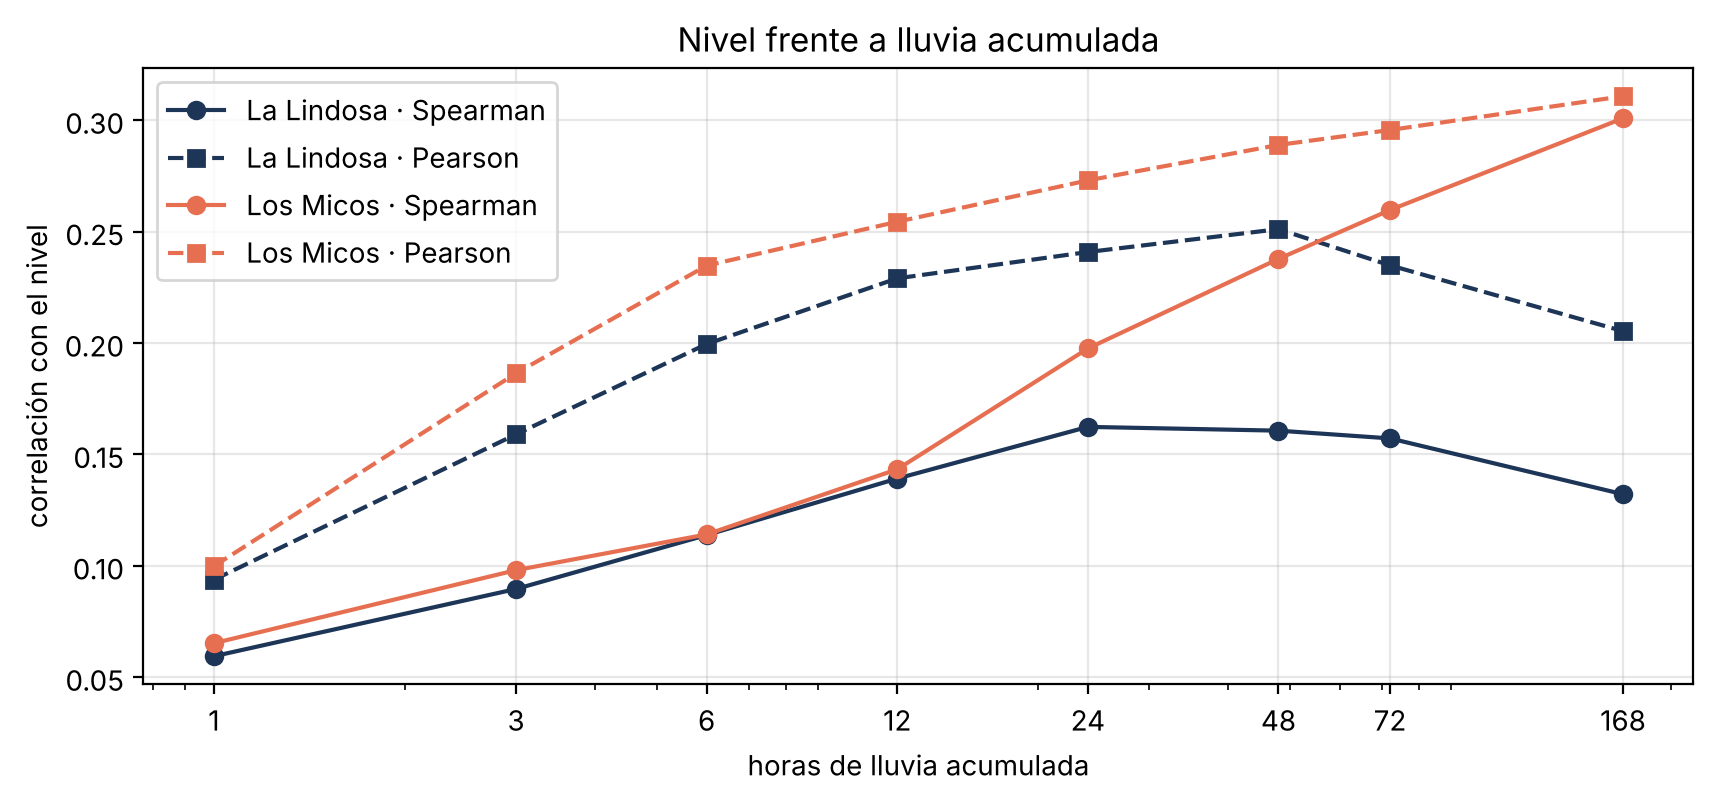

In [10]:
ventanas = [1, 3, 6, 12, 24, 48, 72, 168]
filas = []
for est in ESTACIONES:
    df, r = limpio[est], real[est]
    for n in ventanas:
        # la suma usa la lluvia final (con imputados) para no cortar la ventana; el nivel es solo REAL
        acum = df.lluvia_mm.rolling(n, min_periods=n).sum()
        filas.append({"estación": NOMBRE[est], "ventana (h)": n,
                      "Pearson": r.nivel_m.corr(acum), "Spearman": r.nivel_m.corr(acum, method="spearman")})
acumulada = pd.DataFrame(filas)
display(acumulada.pivot(index="ventana (h)", columns="estación", values=["Pearson", "Spearman"]))

fig, ax = plt.subplots(figsize=(10, 4))
for est in ESTACIONES:
    a = acumulada[acumulada["estación"] == NOMBRE[est]]
    ax.plot(a["ventana (h)"], a.Spearman, marker="o", color=COLOR[est], label=f"{NOMBRE[est]} · Spearman")
    ax.plot(a["ventana (h)"], a.Pearson, marker="s", ls="--", color=COLOR[est], label=f"{NOMBRE[est]} · Pearson")
ax.set_xscale("log")
ax.set_xticks(ventanas, ventanas)
ax.set_xlabel("horas de lluvia acumulada")
ax.set_ylabel("correlación con el nivel")
ax.set_title("Nivel frente a lluvia acumulada")
ax.legend()
plt.show()

### 7.2 Correlación cruzada: ¿cuántas horas después de la lluvia sube el río?

Se correlaciona la **lluvia de hace *k* horas** con el **cambio de nivel** de la hora actual (nivel ahora − nivel hace una hora), para *k* = 0 a 24 h. Se usa el cambio de nivel y no el nivel mismo porque el nivel cambia muy despacio y eso "aplana" la curva y esconde el retraso. El pico de la curva indica el **tiempo de respuesta** típico del río en esa estación.

La Lindosa: la mayor correlación (r = 0.20) se da con la lluvia de hace 0 h
Los Micos: la mayor correlación (r = 0.31) se da con la lluvia de hace 1 h


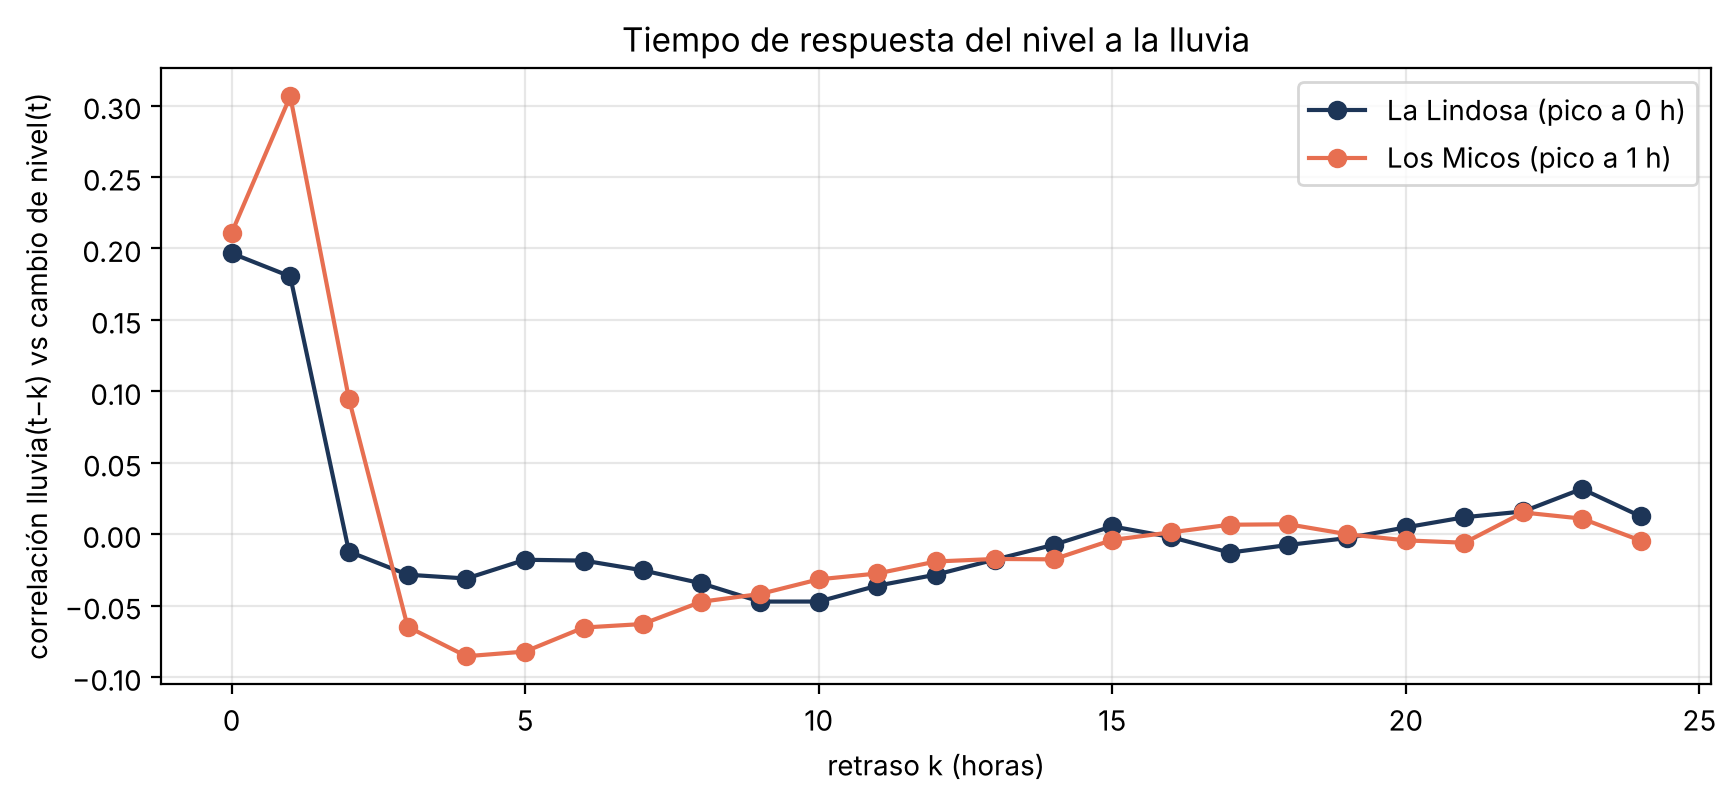

In [11]:
retrasos = range(0, 25)
fig, ax = plt.subplots(figsize=(10, 4))
for est in ESTACIONES:
    r = real[est]
    cambio = r.nivel_m.diff()
    cc = [cambio.corr(r.lluvia_mm.shift(k)) for k in retrasos]
    k_max = int(np.nanargmax(cc))
    ax.plot(list(retrasos), cc, marker="o", color=COLOR[est], label=f"{NOMBRE[est]} (pico a {k_max} h)")
    print(f"{NOMBRE[est]}: la mayor correlación (r = {cc[k_max]:.2f}) se da con la lluvia de hace {k_max} h")
ax.set_xlabel("retraso k (horas)")
ax.set_ylabel("correlación lluvia(t−k) vs cambio de nivel(t)")
ax.set_title("Tiempo de respuesta del nivel a la lluvia")
ax.legend()
plt.show()

## 8. Relación entre las dos estaciones

¿Suben juntas? ¿Una responde antes que la otra? Se repite la correlación cruzada, ahora entre los **cambios de nivel** de las dos estaciones, con desfases de −24 a +24 h. Un pico en un desfase positivo significa que **Los Micos se mueve después** que La Lindosa; negativo, lo contrario.

También se compara la lluvia diaria de las dos estaciones: si están en la misma zona, deberían llover más o menos los mismos días.

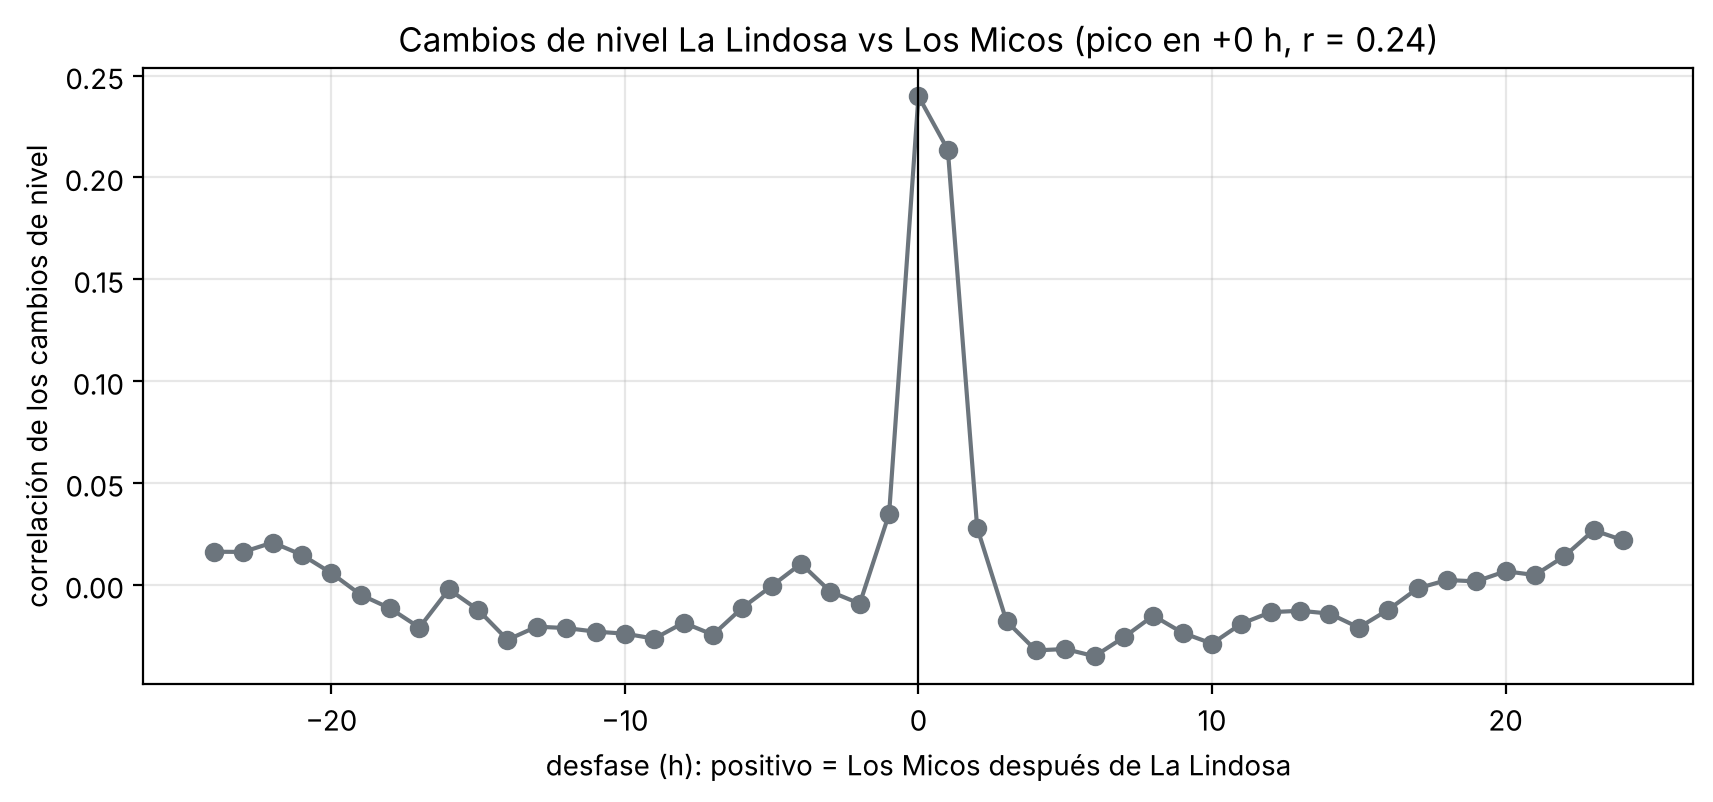

Lluvia diaria entre estaciones: Pearson = 0.67, Spearman = 0.53
Nivel medio diario entre estaciones: Spearman = 0.13


In [12]:
d_ll = real["La_Lindosa"].nivel_m.diff()
d_lm = real["Los_Micos"].nivel_m.diff()
desfases = range(-24, 25)
cc = pd.Series([d_ll.corr(d_lm.shift(-k)) for k in desfases], index=list(desfases))
k_max = int(cc.idxmax())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cc.index, cc.values, marker="o", color="#6c757d")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("desfase (h): positivo = Los Micos después de La Lindosa")
ax.set_ylabel("correlación de los cambios de nivel")
ax.set_title(f"Cambios de nivel La Lindosa vs Los Micos (pico en {k_max:+d} h, r = {cc.max():.2f})")
plt.show()

lluvia_diaria = pd.DataFrame({NOMBRE[e]: real[e].lluvia_mm.resample("D").sum(min_count=20) for e in ESTACIONES})
print("Lluvia diaria entre estaciones: Pearson = "
      f"{lluvia_diaria.corr().iloc[0, 1]:.2f}, Spearman = {lluvia_diaria.corr('spearman').iloc[0, 1]:.2f}")
print("Nivel medio diario entre estaciones: Spearman = "
      f"{diaria['nivel_m Lindosa'].corr(diaria['nivel_m Micos'], method='spearman'):.2f}")

**Lectura:** los cambios de nivel de las dos estaciones ocurren casi **a la vez** (pico en 0 h y todavía alto a +1 h, es decir, Los Micos tiende a responder igual o una hora después). La lluvia diaria de las dos estaciones está bastante correlacionada (r ≈ 0,67): llueve más o menos los mismos días en ambas. En cambio, el nivel medio diario de una casi no se relaciona con el de la otra (ρ ≈ 0,13), por los cambios de nivel de base de cada una a lo largo de los años.

## 9. Conclusiones

1. **Las series limpias son utilizables:** más del 90 % de las horas de nivel son observadas (REAL) y menos del 8 % viene del promedio histórico (MEDIA). Los valores REAL no se modificaron.
2. **La correlación instantánea entre lluvia y nivel es débil** (r ≈ 0,09-0,10 hora a hora), igual que en el artículo. Pero **la lluvia acumulada de las horas previas sí se relaciona con el nivel** (r ≈ 0,25-0,31 con 24-168 h de lluvia acumulada), y el cambio de nivel responde a la lluvia de la misma hora o de la hora anterior. Es decir: la lluvia sí es útil para predecir, siempre que el modelo reciba **la lluvia de las horas y días anteriores** (por ejemplo acumulados de 1, 6, 24 y 72 h), no solo la de la hora actual.
3. **La respuesta es rápida** (0-1 h entre lluvia y subida). Un horizonte de predicción de varias horas dependerá más de la tendencia reciente del propio nivel y de la lluvia acumulada que de la lluvia en el instante.
4. **La temperatura casi no se relaciona con el nivel** (|r| < 0,15). Sirve más como variable de contexto (hora del día, temporada) que como predictor directo.
5. **Las dos estaciones reciben lluvias parecidas y sus niveles se mueven a la vez**, así que cada una puede servir de apoyo a la otra (por ejemplo, usar la lluvia de ambas como entrada).
6. **Pendientes para confirmar con el operador (CAM):** el cambio de nivel de base en ambas estaciones (Los Micos 2021-2022 y el escalón de diciembre de 2023; La Lindosa 2023-2025), la lluvia muy baja de Los Micos en 2025, la lluvia baja de La Lindosa en 2018-2020 y las rachas largas de 0,1 mm/h de lluvia.